In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

PROC = Path("../data/processed")
FIG = Path("../outputs/figures")
TAB = Path("../outputs/tables")

PERIODS = ["Pre-COVID", "During-COVID", "Post-COVID"]
CORE = ["Rice (regular, milled)", "Meat (chicken, whole)", "Onions (red)",
        "Meat (pork)", "Meat (beef, chops with bones)"]

retail = pd.read_csv(PROC / "wfp_retail_tagged.csv", parse_dates=["date"])
retail["ym"] = retail["date"].dt.to_period("M")
retail["mnum"] = retail["date"].dt.year * 12 + retail["date"].dt.month  # month counter

assert set(CORE) <= set(retail["commodity"]), "A core commodity name does not match!"
core = retail[retail["commodity"].isin(CORE)].copy()
print("Core rows (before thin-window removal):", len(core))
print("Markets:", core["market_id"].nunique(), "| Regions:", core["admin1"].nunique())

Core rows (before thin-window removal): 29971
Markets: 97 | Regions: 17


In [2]:
THIN_START, THIN_END = pd.Period("2019-06", "M"), pd.Period("2020-02", "M")
core["thin_window"] = (core["ym"] >= THIN_START) & (core["ym"] <= THIN_END)
print("Rows in thin window (dropped):", int(core["thin_window"].sum()))

core = core[~core["thin_window"]].drop(columns="thin_window").copy()
core["period"] = pd.Categorical(core["period"], PERIODS, ordered=True)
print("Usable rows:", len(core))

print("\nRows per period:\n", core.groupby("period", observed=True).size())
print("\nRows per commodity:\n", core["commodity"].value_counts())
print("\nMarkets per period:\n", core.groupby("period", observed=True)["market_id"].nunique())

# Integrity checks
print("\nDuplicate (market, commodity, month):",
      core.duplicated(["market_id", "commodity_id", "ym"]).sum())
print("Non-positive prices:", int((core["price"] <= 0).sum()))
print("Units   :", core["unit"].unique())
print("Currency:", core["currency"].unique())

Rows in thin window (dropped): 80
Usable rows: 29891

Rows per period:
 period
Pre-COVID        3334
During-COVID    13244
Post-COVID      13313
dtype: int64

Rows per commodity:
 commodity
Rice (regular, milled)           6597
Meat (pork)                      6278
Meat (beef, chops with bones)    6035
Meat (chicken, whole)            5550
Onions (red)                     5431
Name: count, dtype: int64

Markets per period:
 period
Pre-COVID       17
During-COVID    83
Post-COVID      83
Name: market_id, dtype: int64

Duplicate (market, commodity, month): 0
Non-positive prices: 0
Units   : <StringArray>
['KG']
Length: 1, dtype: str
Currency: <StringArray>
['PHP']
Length: 1, dtype: str


In [3]:
core = core.sort_values(["market_id", "commodity_id", "date"]).copy()
core["log_price"] = np.log(core["price"])

g = core.groupby(["market_id", "commodity_id"])
core["lr"] = g["log_price"].diff()
core["gap"] = g["mnum"].diff()
core.loc[core["gap"] != 1, "lr"] = np.nan      # only count true month-to-month changes

JUMP = 0.5   # |log change| > 0.5  (roughly a +65% or -39% move in one month)
core["flag_jump"] = core["lr"].abs() > JUMP

print("Valid month-to-month returns:", int(core["lr"].notna().sum()))
print("Flagged |lr| > 0.5:", int(core["flag_jump"].sum()))
print("|lr| > 0.3        :", int((core["lr"].abs() > 0.3).sum()))

flags = core[core["flag_jump"]]
print("\nFlags by commodity:\n", flags["commodity"].value_counts())
print("\nFlags by year:\n", flags["date"].dt.year.value_counts().sort_index())

display(flags.reindex(flags["lr"].abs().sort_values(ascending=False).index)
             [["date", "market", "admin1", "commodity", "price", "lr"]].head(10))

Valid month-to-month returns: 29304
Flagged |lr| > 0.5: 111
|lr| > 0.3        : 535

Flags by commodity:
 commodity
Onions (red)              110
Rice (regular, milled)      1
Name: count, dtype: int64

Flags by year:
 date
2016     1
2017     1
2020     1
2021     1
2022    32
2023    68
2025     4
2026     3
Name: count, dtype: int64


,date,market,admin1,commodity,price,lr
109736,2023-04-15,Negros Occidental,Region VI,Onions (red),134.75,-0.895308
102512,2023-01-15,Bukidnon,Region X,Onions (red),430.63,0.848250
76082,2022-03-15,Pampanga,Region III,Onions (red),68.75,-0.840815
106463,2023-03-15,Cavite,Region IV-A,Onions (red),125.00,-0.824175
105800,2023-03-15,Benguet,Cordillera Administrative region,Onions (red),180.50,-0.822862
75769,2022-03-15,Ilocos Sur,Region I,Onions (red),73.75,-0.805264
74870,2022-02-15,Lanao del Norte,Region X,Onions (red),131.67,-0.804403
75157,2022-02-15,Sarangani,Region XII,Onions (red),146.25,-0.790786
101195,2023-01-15,Bataan,Region III,Onions (red),605.00,0.781644
74003,2022-02-15,Zamboanga Sibugay,Region IX,Onions (red),166.67,-0.779296


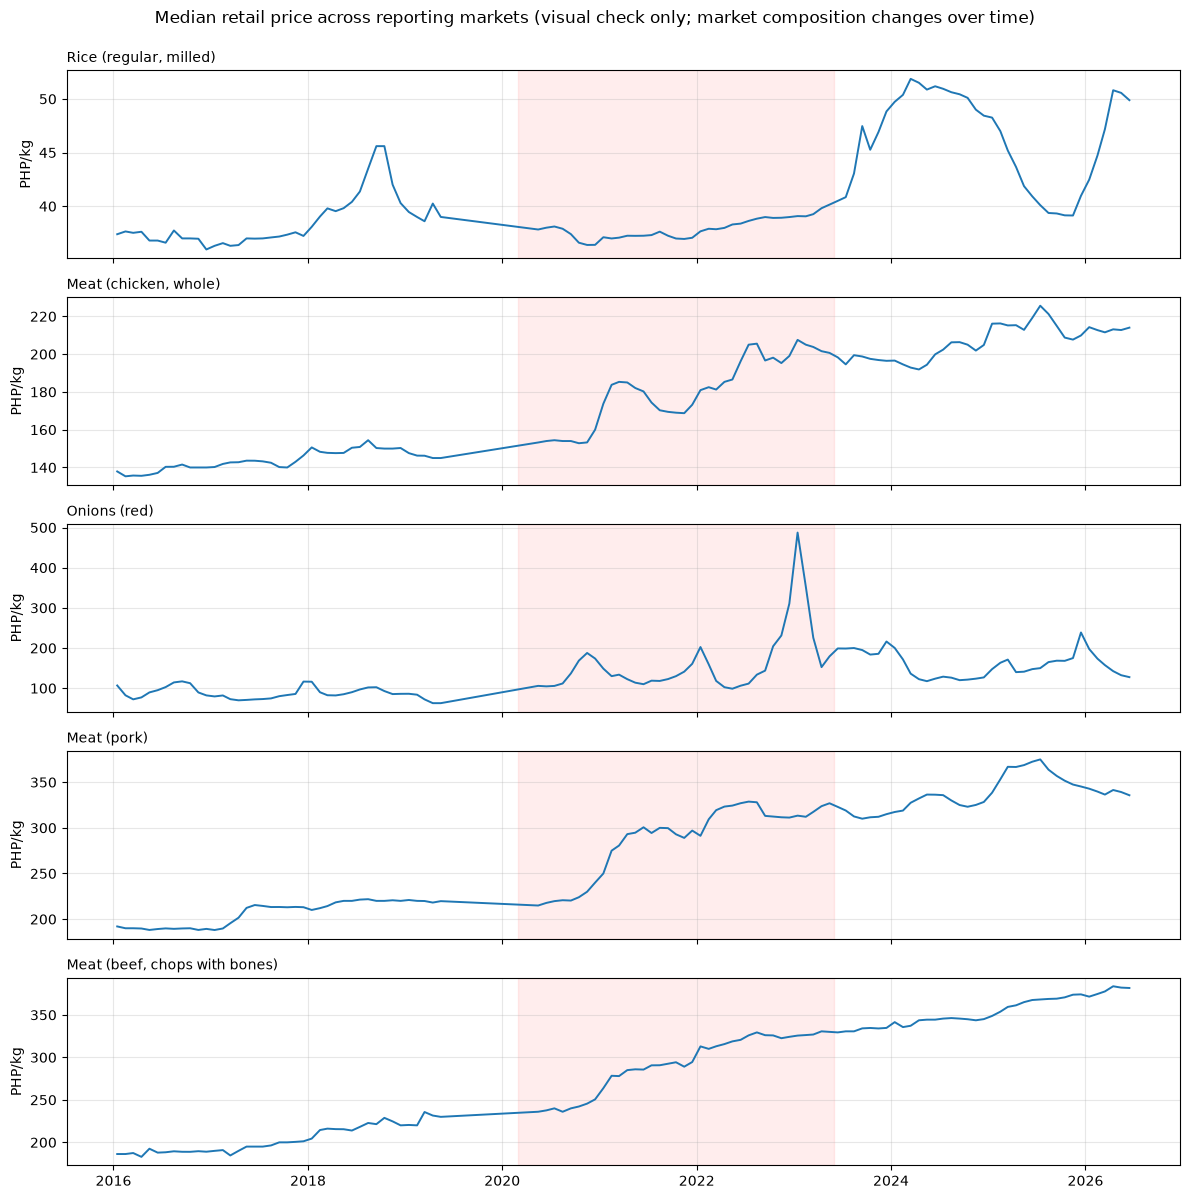

In [4]:
monthly_med = (core.groupby(["commodity", "date"])["price"].median().unstack("commodity"))

fig, axes = plt.subplots(len(CORE), 1, figsize=(12, 12), sharex=True)
for ax, c in zip(axes, CORE):
    ax.plot(monthly_med.index, monthly_med[c], lw=1.4)
    ax.set_ylabel("PHP/kg")
    ax.set_title(c, fontsize=10, loc="left")
    ax.axvspan(pd.Timestamp("2020-03-01"), pd.Timestamp("2023-05-31"), color="red", alpha=0.07)
    ax.grid(alpha=0.3)
fig.suptitle("Median retail price across reporting markets (visual check only; "
             "market composition changes over time)", y=0.995)
plt.tight_layout()
plt.savefig(FIG / "04_core_price_overview.png", dpi=150)
plt.show()

In [5]:
keep = ["date", "period", "admin1", "admin2", "market_id", "market", "commodity",
        "price", "log_price", "lr", "flag_jump"]
out = core[keep].copy()
out.to_csv(PROC / "core_retail_clean.csv", index=False)
flags.to_csv(TAB / "04_flagged_jumps.csv", index=False)
print("Saved", len(out), "rows to", PROC / "core_retail_clean.csv")

Saved 29891 rows to ..\data\processed\core_retail_clean.csv
